# T**ask 1– Load and prepare the data**

# 1.1 Download detect dataset.csv from Kaggle into data/ and load it with the loader in the Appendix. Print the shape, the column names and the first five rows.

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Upload detect_dataset.csv
uploaded = files.upload()

print("**** File Uploaded Successfully ****")

Saving detect_dataset.csv to detect_dataset.csv
**** File Uploaded Successfully ****


# 1.1.1 Load the CSV file

In [2]:
# Get the uploaded file name
file_name = list(uploaded.keys())[0]

# Load dataset
df = pd.read_csv(file_name)

print("**** Dataset Loaded ****")
print("File Name:", file_name)

**** Dataset Loaded ****
File Name: detect_dataset.csv


# 1.1.2 Print the shape

In [3]:
print("**** Dataset Shape ****")
print(df.shape)

**** Dataset Shape ****
(12001, 9)


# 1.1.3 Print column names





In [4]:
print("**** Column Names ****")
print(df.columns)

**** Column Names ****
Index(['Output (S)', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc', 'Unnamed: 7',
       'Unnamed: 8'],
      dtype='object')


# 1.1.4 Print first five rows

In [5]:
print("**** First Five Rows ****")
print(df.head())

**** First Five Rows ****
   Output (S)          Ia        Ib          Ic        Va        Vb        Vc  \
0           0 -170.472196  9.219613  161.252583  0.054490 -0.659921  0.605431   
1           0 -122.235754  6.168667  116.067087  0.102000 -0.628612  0.526202   
2           0  -90.161474  3.813632   86.347841  0.141026 -0.605277  0.464251   
3           0  -79.904916  2.398803   77.506112  0.156272 -0.602235  0.445963   
4           0  -63.885255  0.590667   63.294587  0.180451 -0.591501  0.411050   

   Unnamed: 7  Unnamed: 8  
0         NaN         NaN  
1         NaN         NaN  
2         NaN         NaN  
3         NaN         NaN  
4         NaN         NaN  


# **1.2 Inspect Columns, Remove Uninformative Columns, Rename Label, Check Numeric Data and Missing Values**

# 1.2.1 Inspect all columns

In [6]:
print("**** All Columns ****")

for column in df.columns:
    print(column)

**** All Columns ****
Output (S)
Ia
Ib
Ic
Va
Vb
Vc
Unnamed: 7
Unnamed: 8


# 1.2.2 Check information in every column

In [7]:
print("**** Column Information ****")
print(df.info())

**** Column Information ****
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12001 entries, 0 to 12000
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Output (S)  12001 non-null  int64  
 1   Ia          12001 non-null  float64
 2   Ib          12001 non-null  float64
 3   Ic          12001 non-null  float64
 4   Va          12001 non-null  float64
 5   Vb          12001 non-null  float64
 6   Vc          12001 non-null  float64
 7   Unnamed: 7  0 non-null      float64
 8   Unnamed: 8  0 non-null      float64
dtypes: float64(8), int64(1)
memory usage: 843.9 KB
None


# 1.2.3 Check whether columns are completely empty

In [8]:
print("**** Missing Values in Each Column ****")
print(df.isnull().sum())
# Now identify columns that contain no information at all
print("**** Completely Empty Columns ****")
empty_columns = df.columns[df.isnull().all()].tolist()
print(empty_columns)

**** Missing Values in Each Column ****
Output (S)        0
Ia                0
Ib                0
Ic                0
Va                0
Vb                0
Vc                0
Unnamed: 7    12001
Unnamed: 8    12001
dtype: int64
**** Completely Empty Columns ****
['Unnamed: 7', 'Unnamed: 8']


# 1.2.4 Remove columns carrying no information

In [9]:
# Remove completely empty columns
df = df.drop(columns=empty_columns)

print("**** Columns After Removing Empty Columns ****")
print(df.columns)

**** Columns After Removing Empty Columns ****
Index(['Output (S)', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc'], dtype='object')


# 1.2.5 Rename the label column to fault

In [10]:
df = df.rename(columns={"Output (S)": "fault"})
print("**** Columns After Renaming Label ****")
print(df.columns)

**** Columns After Renaming Label ****
Index(['fault', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc'], dtype='object')


# 1.2.6 Check the six measurement columns

In [11]:
features = ["Ia", "Ib", "Ic", "Va", "Vb", "Vc"]
print("**** Six Measurement Columns ****")
for column in features:
    print(column)

**** Six Measurement Columns ****
Ia
Ib
Ic
Va
Vb
Vc


# 1.2.7 Check data types

In [12]:
print("**** Data Types of Six Measurements ****")
print(df[features].dtypes)

**** Data Types of Six Measurements ****
Ia    float64
Ib    float64
Ic    float64
Va    float64
Vb    float64
Vc    float64
dtype: object


# 1.2.8 Convert measurement columns to numeric

In [13]:
for column in features:
    df[column] = pd.to_numeric(df[column], errors="coerce")
print("**** Data Types After Conversion ****")
print(df[features].dtypes)

**** Data Types After Conversion ****
Ia    float64
Ib    float64
Ic    float64
Va    float64
Vb    float64
Vc    float64
dtype: object


# 1.2.9 Report missing values per column

In [14]:
print("**** Missing Values Per Column ****")
print(df.isnull().sum())

**** Missing Values Per Column ****
fault    0
Ia       0
Ib       0
Ic       0
Va       0
Vb       0
Vc       0
dtype: int64


# 1.2.10 Check the final datase

In [15]:
print("**** Final Dataset ****")
print("Shape:")
print(df.shape)
print("\nColumns:")
print(df.columns)
print("\nFirst Five Rows:")
print(df.head())

**** Final Dataset ****
Shape:
(12001, 7)

Columns:
Index(['fault', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc'], dtype='object')

First Five Rows:
   fault          Ia        Ib          Ic        Va        Vb        Vc
0      0 -170.472196  9.219613  161.252583  0.054490 -0.659921  0.605431
1      0 -122.235754  6.168667  116.067087  0.102000 -0.628612  0.526202
2      0  -90.161474  3.813632   86.347841  0.141026 -0.605277  0.464251
3      0  -79.904916  2.398803   77.506112  0.156272 -0.602235  0.445963
4      0  -63.885255  0.590667   63.294587  0.180451 -0.591501  0.411050


# 1.3 Report Number of Fault and No-Fault Rows

# 1.3.1 Check unique labels

In [16]:
print("**** Unique Fault Labels ****")
print(df["fault"].unique())

**** Unique Fault Labels ****
[0 1]


# 1.3.2 Count fault = 0

In [17]:
no_fault_count = (df["fault"] == 0).sum()
print("**** Number of Rows with fault = 0 ****")
print(no_fault_count)

**** Number of Rows with fault = 0 ****
6505


# 1.3.3 Count fault = 1

In [18]:
fault_count = (df["fault"] == 1).sum()
print("**** Number of Rows with fault = 1 ****")
print(fault_count)

**** Number of Rows with fault = 1 ****
5496


# 1.3.4 Display both counts together

In [19]:
print("**** Fault Class Counts ****")
print("fault = 0:", no_fault_count)
print("fault = 1:", fault_count)
print("Total Rows:", len(df))

**** Fault Class Counts ****
fault = 0: 6505
fault = 1: 5496
Total Rows: 12001


# 1.4 Split the rows with exactly this code, so every group has the same split: 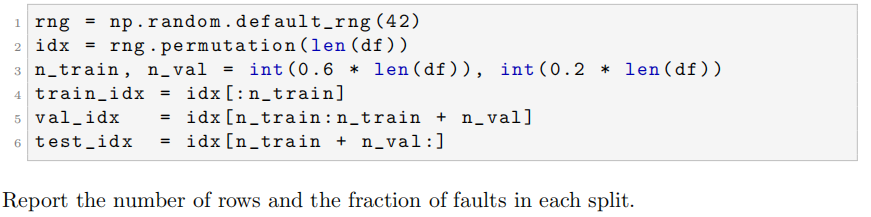

# 1.4.1 Create the exact split

In [20]:
rng = np.random.default_rng(42)
idx = rng.permutation(len(df))
n_train, n_val = int(0.6 * len(df)), int(0.2 * len(df))
train_idx = idx[:n_train]
val_idx = idx[n_train:n_train + n_val]
test_idx = idx[n_train + n_val:]
print("**** Split Created ****")

**** Split Created ****


# 1.4.2 Create Training, Validation and Testing Data

In [21]:
train_df = df.iloc[train_idx].copy()
val_df = df.iloc[val_idx].copy()
test_df = df.iloc[test_idx].copy()
print("**** Dataset Sizes ****")
print("Training Rows:", len(train_df))
print("Validation Rows:", len(val_df))
print("Testing Rows:", len(test_df))

**** Dataset Sizes ****
Training Rows: 7200
Validation Rows: 2400
Testing Rows: 2401


# 1.4.3 Calculate the fraction of faults in Training Data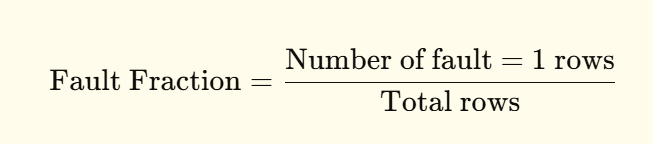

In [22]:
train_fault_fraction = train_df["fault"].mean()
print("**** Training Set ****")
print("Rows:", len(train_df))
print("Fault Fraction:", train_fault_fraction)

**** Training Set ****
Rows: 7200
Fault Fraction: 0.46069444444444446


# 1.4.4 Calculate the fraction of faults in Validation Data

In [23]:
val_fault_fraction = val_df["fault"].mean()
print("**** Validation Set ****")
print("Rows:", len(val_df))
print("Fault Fraction:", val_fault_fraction)

**** Validation Set ****
Rows: 2400
Fault Fraction: 0.45125


# 1.4.5 Calculate the fraction of faults in Testing Data

In [24]:
test_fault_fraction = test_df["fault"].mean()
print("**** Testing Set ****")
print("Rows:", len(test_df))
print("Fault Fraction:", test_fault_fraction)

**** Testing Set ****
Rows: 2401
Fault Fraction: 0.4564764681382757


# 1.4.6 Report All Split Results

In [25]:
print("**************************************")
print("        DATASET SPLIT RESULTS")
print("**************************************")
print("\n^^^^Training Set^^^^")
print("Rows:", len(train_df))
print("Fault Fraction:", train_fault_fraction)
print("\n^^^^Validation Set^^^^")
print("Rows:", len(val_df))
print("Fault Fraction:", val_fault_fraction)
print("\n^^^^Testing Set^^^^")
print("Rows:", len(test_df))
print("Fault Fraction:", test_fault_fraction)

**************************************
        DATASET SPLIT RESULTS
**************************************

^^^^Training Set^^^^
Rows: 7200
Fault Fraction: 0.46069444444444446

^^^^Validation Set^^^^
Rows: 2400
Fault Fraction: 0.45125

^^^^Testing Set^^^^
Rows: 2401
Fault Fraction: 0.4564764681382757


# 1.4.7 Verify Total Number of Rows

In [26]:
print("**** Split Verification ****")
print("Original Rows:", len(df))
print(
    "Train + Validation + Test:",
    len(train_df) + len(val_df) + len(test_df))

**** Split Verification ****
Original Rows: 12001
Train + Validation + Test: 12001


# 1.5 Standardise every feature: subtract the training mean and divide by the training standard deviation. Use the training statistics for all three splits.

# 1.5.1 Separate Features and Labels

In [27]:
features = ["Ia", "Ib", "Ic", "Va", "Vb", "Vc"]

X_train = train_df[features].to_numpy()
y_train = train_df["fault"].to_numpy()
X_val = val_df[features].to_numpy()
y_val = val_df["fault"].to_numpy()
X_test = test_df[features].to_numpy()
y_test = test_df["fault"].to_numpy()
print("**** Feature and Label Shapes ****")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

**** Feature and Label Shapes ****
X_train: (7200, 6)
y_train: (7200,)
X_val: (2400, 6)
y_val: (2400,)
X_test: (2401, 6)
y_test: (2401,)


# 1.5.2 Calculate Training Mean

In [28]:
train_mean = X_train.mean(axis=0)
print("**** Training Mean ****")
for i in range(len(features)):
    print(features[i], "=", train_mean[i])

**** Training Mean ****
Ia = 5.045347551502084
Ib = -28.35520359696486
Ic = 24.988539440415277
Va = 0.0124287916675
Vb = -0.016679491909305556
Vc = 0.004250643307361112


# 1.5.3 Calculate Training Standard Deviation

In [29]:
train_std = X_train.std(axis=0)
print("**** Training Standard Deviation ****")
for i in range(len(features)):
    print(features[i], "=", train_std[i])

**** Training Standard Deviation ****
Ia = 373.23462443442617
Ib = 358.66496732633874
Ic = 303.5968196154384
Va = 0.34466135694046196
Vb = 0.35873354336849256
Vc = 0.3490485134006526


# 1.5.4 Standardise Training Data
#        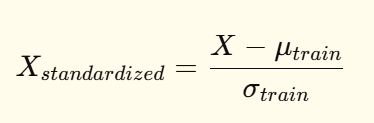

In [30]:
X_train_std = (X_train - train_mean) / train_std
print("**** Standardised Training Data ****")
print(X_train_std[:5])

**** Standardised Training Data ****
[[-0.16225357  0.10463753  0.07788891  0.72059684 -1.61299231  0.94620835]
 [-2.11705846  0.20076364  2.36685277 -0.13659305  0.15371362 -0.02310231]
 [ 0.60076442 -2.34943446 -0.25025125 -0.1240972   0.47197412 -0.36253237]
 [-0.14310009  0.10457439  0.03706186  1.01050498 -1.5745555   0.62044073]
 [ 0.44830801 -0.02243614  0.08000462  1.00638534 -1.6220906   0.67336264]]


# 1.5.5 Standardise Validation Data

In [31]:
X_val_std = (X_val - train_mean) / train_std
print("**** Standardised Validation Data ****")
print(X_val_std[:5])

**** Standardised Validation Data ****
[[-2.18275002  0.35290222  2.26096991 -0.13197528  0.15666071 -0.03069091]
 [-0.1162852   0.07172904  0.05914455  1.26032592 -1.45587872  0.25179007]
 [-0.17849848  0.28295786 -0.11275036 -1.21658784 -0.47229078  1.68669223]
 [ 0.03009264 -0.07119506  0.09764936  1.71374641 -0.882638   -0.78507783]
 [-0.672139    2.48304036  0.082816    0.05227897 -0.35049724  0.30860075]]


# 1.5.6 Standardise Test Data

In [32]:
X_test_std = (X_test - train_mean) / train_std
print("**** Standardised Test Data ****")
print(X_test_std[:5])

**** Standardised Test Data ****
[[-0.06335739  0.02439044  0.04952413  1.53793612 -1.27835949 -0.20477573]
 [-0.18607949  0.11868641  0.0706102   0.1052871  -1.48087302  1.41799913]
 [ 0.37326523 -0.41324938  0.03082652  0.08288075 -1.43287473  1.39079376]
 [-0.01797671 -0.07673185  0.09534541  1.68874288 -1.0520971  -0.5862275 ]
 [-0.18192264  0.11089285  0.09631037  0.44498126 -1.58639557  1.19102503]]


# 1.5.7 Display Standardisation Statistics

In [33]:
print("**************************************")
print("       STANDARDISATION RESULTS")
print("**************************************")

print(f"{'Feature':<10} {'Mean':>20} {'Std':>20}")
print("-" * 55)

for i in range(len(features)):
    print(f"{features[i]:<10} {train_mean[i]:>20.4f} {train_std[i]:>20.4f}")

**************************************
       STANDARDISATION RESULTS
**************************************
Feature                    Mean                  Std
-------------------------------------------------------
Ia                       5.0453             373.2346
Ib                     -28.3552             358.6650
Ic                      24.9885             303.5968
Va                       0.0124               0.3447
Vb                      -0.0167               0.3587
Vc                       0.0043               0.3490


# 1.5.8 Verify Standardised Training Mean and Verify Standardised Training Standard Deviation

In [34]:
print("**** Mean of Standardised Training Features ****")
print(X_train_std.mean(axis=0))

print("**** Std of Standardised Training Features ****")
print(X_train_std.std(axis=0))

**** Mean of Standardised Training Features ****
[-1.57898386e-17  1.13489465e-17  1.77635684e-17  9.86864911e-18
 -1.48029737e-17 -3.57738530e-17]
**** Std of Standardised Training Features ****
[1. 1. 1. 1. 1. 1.]


# **Task 2 – Exploratory plots**
#

# 2.1 Ia, Ib, Ic against row number for the first 2000 rows, with the background shaded wherever fault = 1. (The rows are consecutive time samples.)

# 2.1.1 Prepare first 2000 raw rows

In [35]:
# Use raw, unstandardised data
raw_df = df.copy()
# Select first 2000 rows
number_of_rows = min(2000, len(raw_df))
plot_df = raw_df.iloc[:number_of_rows].copy()
# Row numbers
row_numbers = np.arange(number_of_rows)
print("**** Task 2.1 Data ****")
print("Number of rows used:", number_of_rows)

**** Task 2.1 Data ****
Number of rows used: 2000


# 2.1.2 Plot Ia, Ib and Ic

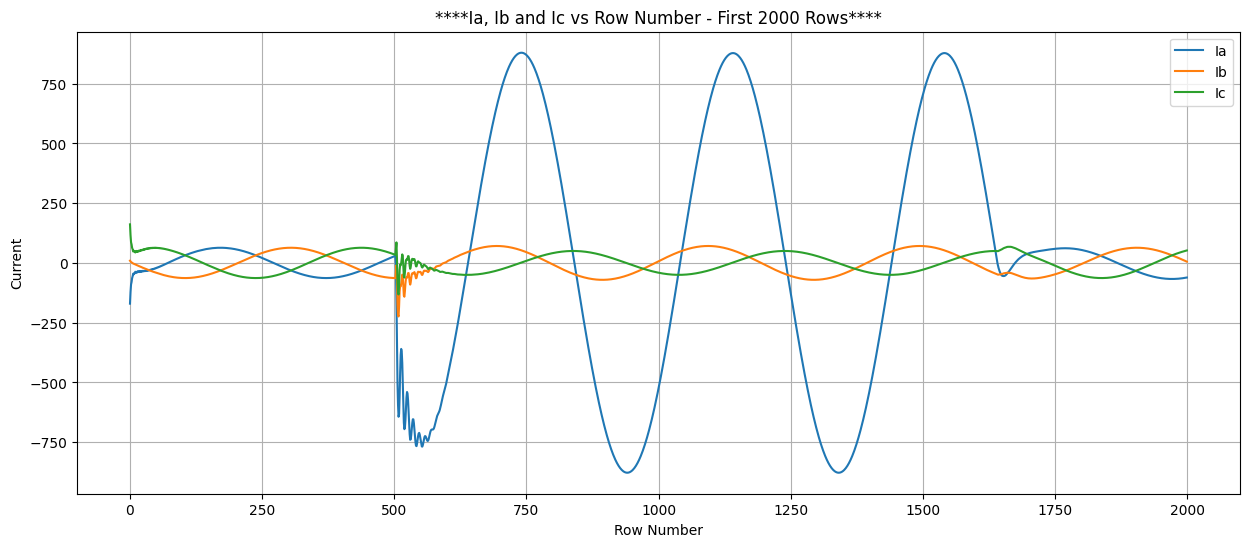

In [36]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 6))
plt.plot( row_numbers,plot_df["Ia"],label="Ia")
plt.plot(row_numbers,plot_df["Ib"],label="Ib")
plt.plot(row_numbers,plot_df["Ic"],label="Ic")
plt.xlabel("Row Number")
plt.ylabel("Current")
plt.title("****Ia, Ib and Ic vs Row Number - First 2000 Rows****")
plt.legend()
plt.grid(True)
plt.show()

# 2.1.3 Shade regions where fault = 1

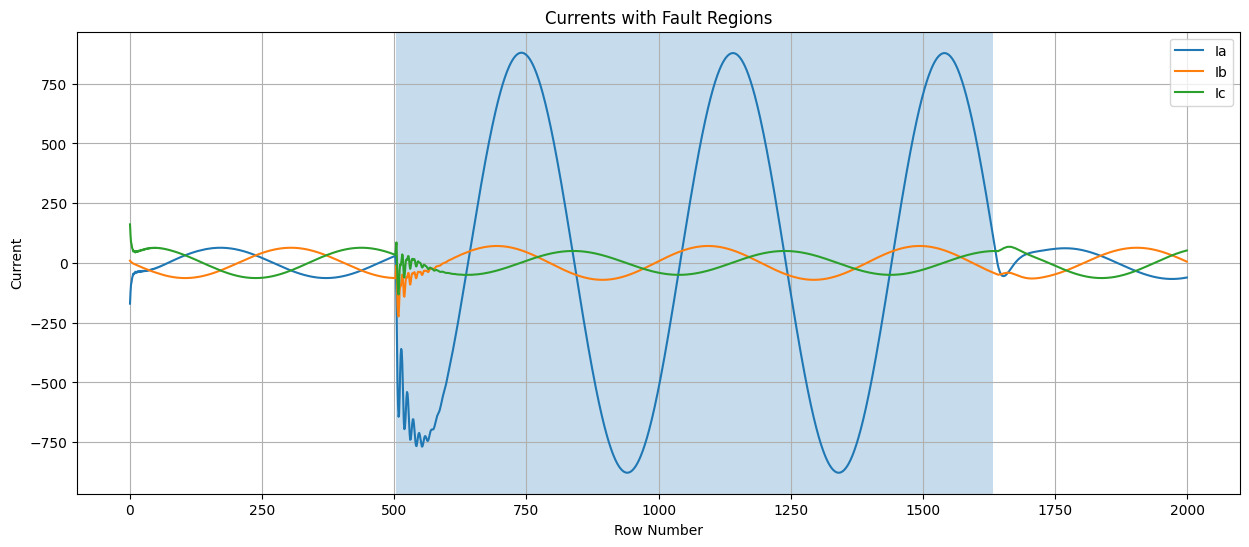

**** Explanation of Plot 2.1 ****
The plot shows the three phase currents Ia, Ib and Ic over the first
2000 consecutive time samples. The shaded background regions indicate
the time samples where fault = 1.

During fault periods, the current signals can change significantly
from their normal operating behaviour. This makes the current
measurements useful for identifying transmission-line faults.



In [37]:
plt.figure(figsize=(15, 6))

plt.plot(row_numbers, plot_df["Ia"], label="Ia")
plt.plot(row_numbers, plot_df["Ib"], label="Ib")
plt.plot(row_numbers, plot_df["Ic"], label="Ic")

for i in range(len(plot_df)):
    if plot_df["fault"].iloc[i] == 1:
        plt.axvspan(i, i + 1, alpha=0.25)

plt.xlabel("Row Number")
plt.ylabel("Current")
plt.title("Currents with Fault Regions")
plt.legend()
plt.grid(True)
plt.show()
print("**** Explanation of Plot 2.1 ****")

print("""The plot shows the three phase currents Ia, Ib and Ic over the first
2000 consecutive time samples. The shaded background regions indicate
the time samples where fault = 1.

During fault periods, the current signals can change significantly
from their normal operating behaviour. This makes the current
measurements useful for identifying transmission-line faults.
""")

# 2.2 Scatter plot of Ia against Ib, coloured by fault

# 2.2.1 Create the scatter plot

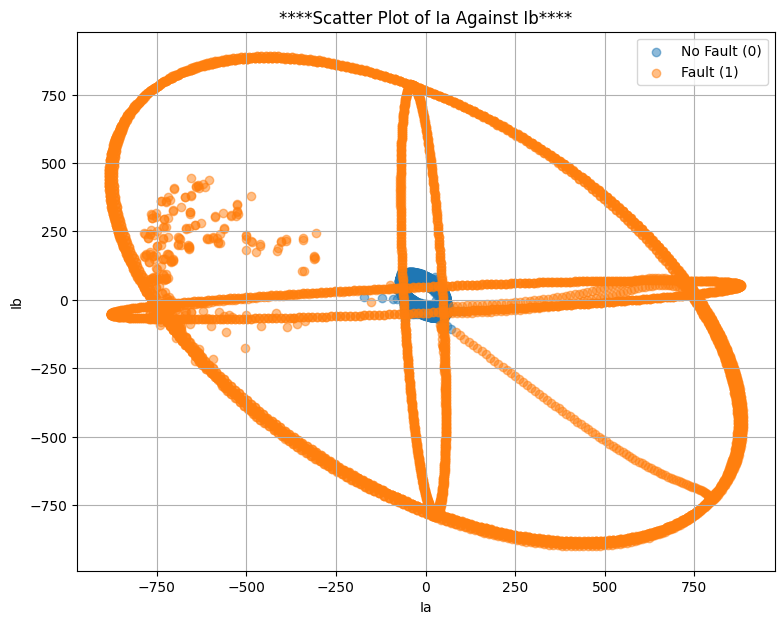

**** Explanation of Plot 2.2 ****

The scatter plot shows the relationship between phase currents Ia and Ib.
Fault and no-fault samples are represented by different colours.
The no-fault samples are concentrated near zero, while fault samples
show a wider range of current values. This indicates that fault
conditions can cause significant changes in phase currents.



In [38]:
# Set figure size
plt.figure(figsize=(9, 7))
# Select no-fault and fault rows
no_fault = raw_df["fault"] == 0
fault = raw_df["fault"] == 1
# Plot no-fault samples
plt.scatter(raw_df.loc[no_fault, "Ia"], raw_df.loc[no_fault, "Ib"], alpha=0.5, label="No Fault (0)")
# Plot fault samples
plt.scatter(raw_df.loc[fault, "Ia"], raw_df.loc[fault, "Ib"], alpha=0.5, label="Fault (1)")
# Add axis labels and title
plt.xlabel("Ia")
plt.ylabel("Ib")
plt.title("****Scatter Plot of Ia Against Ib****")
# Show legend and grid
plt.legend()
plt.grid(True)
# Display the plot
plt.show()
print("**** Explanation of Plot 2.2 ****")
print("""
The scatter plot shows the relationship between phase currents Ia and Ib.
Fault and no-fault samples are represented by different colours.
The no-fault samples are concentrated near zero, while fault samples
show a wider range of current values. This indicates that fault
conditions can cause significant changes in phase currents.
""")


# 2.3 Histogram of Ia for fault rows and for no-fault rows on the same axes.

# 2.3.1 Plot histogram

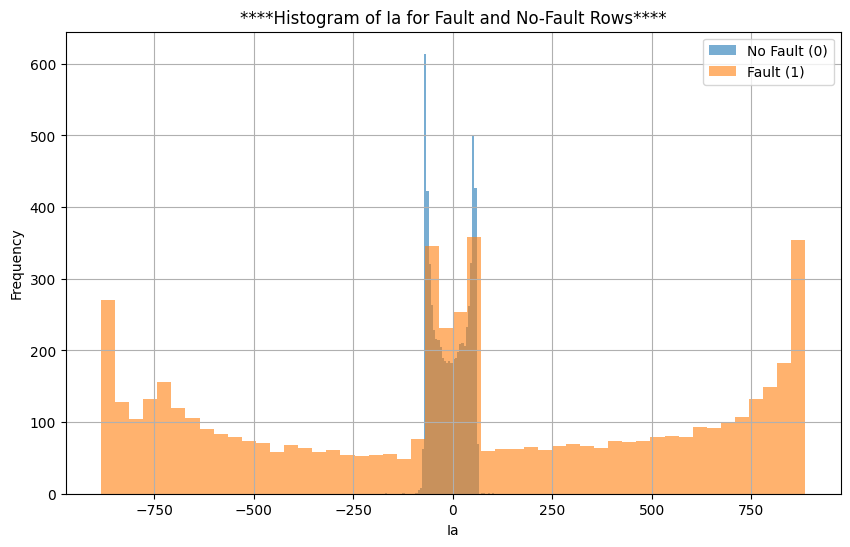

**** Explanation of Plot 2.3 ****

The histogram compares the distribution of phase current Ia under fault and no-fault conditions.
The no-fault samples (blue) are mainly concentrated near zero, while the fault samples (orange)
are spread across a much wider range of current values. However, both distributions overlap
near zero, indicating that Ia alone may not be sufficient to distinguish all fault and no-fault conditions.



In [39]:
plt.figure(figsize=(10, 6))
# Plot Ia distribution for no-fault rows
plt.hist(raw_df.loc[raw_df["fault"] == 0, "Ia"], bins=50, alpha=0.6, label="No Fault (0)")
# Plot Ia distribution for fault rows
plt.hist(raw_df.loc[raw_df["fault"] == 1, "Ia"], bins=50, alpha=0.6, label="Fault (1)")
# Add labels and title
plt.xlabel("Ia")
plt.ylabel("Frequency")
plt.title("****Histogram of Ia for Fault and No-Fault Rows****")
# Show legend, grid, and plot
plt.legend()
plt.grid(True)
plt.show()

print("**** Explanation of Plot 2.3 ****")
print("""
The histogram compares the distribution of phase current Ia under fault and no-fault conditions.
The no-fault samples (blue) are mainly concentrated near zero, while the fault samples (orange)
are spread across a much wider range of current values. However, both distributions overlap
near zero, indicating that Ia alone may not be sufficient to distinguish all fault and no-fault conditions.
""")


# Question:
# After these plots, answer in one paragraph: could a single straight line in the (Ia, Ib) plane separate the two classes? Why, in terms of what a fault does to the current?

In [40]:
print("**** Task 2 Final Discussion ****")

print("""
A single straight line may not perfectly separate the fault and
no-fault classes because their data points overlap. A fault changes
the electrical conditions of the transmission line, causing changes
in phase currents. Since some fault and no-fault samples may have
similar current values, a straight line may not classify all samples
correctly. Therefore, additional features may improve fault detection.
""")

**** Task 2 Final Discussion ****

A single straight line may not perfectly separate the fault and
no-fault classes because their data points overlap. A fault changes
the electrical conditions of the transmission line, causing changes
in phase currents. Since some fault and no-fault samples may have
similar current values, a straight line may not classify all samples
correctly. Therefore, additional features may improve fault detection.



# **TASK 3 — Logistic Regression by Hand**
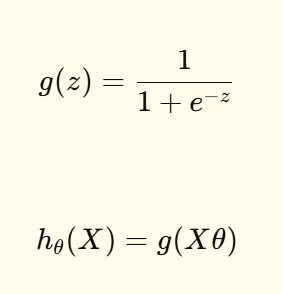

# 3.1 — Sigmoid, Hypothesis and Cost

# 3.1.1 Sigmoid Function and Test Sigmoid

In [41]:
import numpy as np
def sigmoid(z):
    # Prevent numerical overflow
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))
print("**** Sigmoid Function Created ****")
test_values = np.array([-2, -1, 0, 1, 2])
print("**** Sigmoid Test ****")
print(sigmoid(test_values))

**** Sigmoid Function Created ****
**** Sigmoid Test ****
[0.11920292 0.26894142 0.5        0.73105858 0.88079708]


# 3.1.2 Hypothesis Function

In [42]:
def hypothesis(X, theta):
    # Calculate theta transpose times X
    z = X @ theta
    # Apply sigmoid
    h = sigmoid(z)
    return h
print("**** Hypothesis Function Created ****")

**** Hypothesis Function Created ****


# 3.1.3 Cost Function

In [43]:
def cost(X, y, theta):
    # Number of training samples
    n = len(y)
    # Calculate predictions
    h = hypothesis(X, theta)
    # Clip predictions before log
    h = np.clip(
        h,
        1e-12,
        1 - 1e-12
    )
    # Calculate logistic regression cost
    J = -(1 / n) * np.sum(
        y * np.log(h)
        +
        (1 - y) * np.log(1 - h)
    )
    return J
print("**** Cost Function Created ****")

**** Cost Function Created ****


#3.2 — Batch Gradient Descent

#3.2.1 fit_logistic() Function

In [44]:
def fit_logistic(X, y, alpha, n_iters):
    # Number of training rows
    n = X.shape[0]
    # Number of parameters
    number_of_parameters = X.shape[1]
    # Start theta from zero
    theta = np.zeros(number_of_parameters)
    # Store cost after every iteration
    cost_history = []
    # Repeat for required number of iterations
    for iteration in range(n_iters):
        # Calculate hypothesis
        h = hypothesis(X, theta)
        # Calculate error
        error = y - h
        # Calculate gradient
        gradient = (X.T @ error) / n
        # Update theta
        theta = theta + alpha * gradient
        # Calculate and record cost
        J = cost(X, y, theta)
        cost_history.append(J)
    return theta, np.array(cost_history)
print("**** fit_logistic Function Created ****")

**** fit_logistic Function Created ****


#3.3 — Prediction Function

#3.3.1 predict() Function

In [45]:
def predict(X, theta):
    # Calculate probability
    probability = hypothesis(X, theta)
    # Convert probability to class
    predictions = (probability >= 0.5).astype(int)
    return predictions
print("**** Predict Function Created ****")

**** Predict Function Created ****


#3.3.2 Accuracy Function

In [46]:
def accuracy(y_true, y_pred):
    correct = np.sum(y_true == y_pred)
    total = len(y_true)
    result = (correct / total) * 100
    return result
print("**** Accuracy Function Created ****")

**** Accuracy Function Created ****


#3.3.3 Create Set R

In [47]:
# Set R uses the six standardized features
X_R_train = X_train_std.copy()
X_R_val = X_val_std.copy()
X_R_test = X_test_std.copy()
print("**** Set R ****")

print("Training Shape:", X_R_train.shape)
print("Validation Shape:", X_R_val.shape)
print("Testing Shape:", X_R_test.shape)

**** Set R ****
Training Shape: (7200, 6)
Validation Shape: (2400, 6)
Testing Shape: (2401, 6)


#3.3.4 Add Intercept to Set R

In [48]:
# Add intercept column x0 = 1
X_R_train = np.column_stack(
    (
        np.ones(X_R_train.shape[0]),
        X_R_train
    )
)
X_R_val = np.column_stack(
    (
        np.ones(X_R_val.shape[0]),
        X_R_val
    )
)
X_R_test = np.column_stack(
    (
        np.ones(X_R_test.shape[0]),
        X_R_test
    )
)

print("**** Set R With Intercept ****")
print("Training Shape:", X_R_train.shape)
print("Validation Shape:", X_R_val.shape)
print("Testing Shape:", X_R_test.shape)

**** Set R With Intercept ****
Training Shape: (7200, 7)
Validation Shape: (2400, 7)
Testing Shape: (2401, 7)


#3.3.5 Get Raw Values

In [49]:
# Raw values from Task 1
raw_train = X_train.copy()
raw_val = X_val.copy()
raw_test = X_test.copy()
print("**** Raw Data for Set Q ****")

print("Training Shape:", raw_train.shape)
print("Validation Shape:", raw_val.shape)
print("Testing Shape:", raw_test.shape)

**** Raw Data for Set Q ****
Training Shape: (7200, 6)
Validation Shape: (2400, 6)
Testing Shape: (2401, 6)


#3.3.6 Calculate Squares From Raw Values

In [50]:
# Calculate squares BEFORE standardisation
train_squares = raw_train ** 2
val_squares = raw_val ** 2
test_squares = raw_test ** 2

print("**** Squared Features Created ****")

print("Training Square Shape:", train_squares.shape)
print("Validation Square Shape:", val_squares.shape)
print("Testing Square Shape:", test_squares.shape)

**** Squared Features Created ****
Training Square Shape: (7200, 6)
Validation Square Shape: (2400, 6)
Testing Square Shape: (2401, 6)


#3.3.7 Combine Raw Features and Squares

In [51]:
# Combine six raw features + six squared features
X_Q_train_raw = np.column_stack(
    (
        raw_train,
        train_squares
    )
)

X_Q_val_raw = np.column_stack(
    (
        raw_val,
        val_squares
    )
)

X_Q_test_raw = np.column_stack(
    (
        raw_test,
        test_squares
    )
)
print("**** Set Q Raw Data ****")
print("Training Shape:", X_Q_train_raw.shape)
print("Validation Shape:", X_Q_val_raw.shape)
print("Testing Shape:", X_Q_test_raw.shape)

**** Set Q Raw Data ****
Training Shape: (7200, 12)
Validation Shape: (2400, 12)
Testing Shape: (2401, 12)


#3.3.8 Calculate Set Q Training Mean

In [52]:
# Mean of the 12 Set Q features
# Use training data only
Q_mean = X_Q_train_raw.mean(axis=0)
print("**** Set Q Training Mean ****")
for i in range(len(Q_mean)):

    print(
        "Feature",
        i + 1,
        "=",
        Q_mean[i]
    )

**** Set Q Training Mean ****
Feature 1 = 5.045347551502079
Feature 2 = -28.355203596964987
Feature 3 = 24.988539440415263
Feature 4 = 0.012428791667499989
Feature 5 = -0.01667949190930563
Feature 6 = 0.004250643307361116
Feature 7 = 139329.54040862274
Feature 8 = 129444.57635822908
Feature 9 = 92795.45598397453
Feature 10 = 0.11894592583035495
Feature 11 = 0.1289679605880668
Feature 12 = 0.12185293267573157


# 3.3.9 Calculate Set Q Training Standard Deviation

In [53]:
# Standard deviation of the 12 Set Q features
# Use training data only
Q_std = X_Q_train_raw.std(axis=0)
print("**** Set Q Training Standard Deviation ****")
for i in range(len(Q_std)):

    print(
        "Feature",
        i + 1,
        "=",
        Q_std[i]
    )

**** Set Q Training Standard Deviation ****
Feature 1 = 373.234624434426
Feature 2 = 358.6649673263394
Feature 3 = 303.59681961543765
Feature 4 = 0.3446613569404622
Feature 5 = 0.3587335433684926
Feature 6 = 0.3490485134006529
Feature 7 = 240450.61182597393
Feature 8 = 233126.91310538648
Feature 9 = 203220.0631568904
Feature 10 = 0.1277376195907853
Feature 11 = 0.1332313210772683
Feature 12 = 0.12418851054151303


#3.3.10 Standardize Set Q Training Data

In [54]:
X_Q_train_std = (
    X_Q_train_raw - Q_mean
) / Q_std

print("**** Standardized Set Q Training Data ****")
print(X_Q_train_std[:5])

**** Standardized Set Q Training Data ****
[[-0.16225357  0.10463753  0.07788891  0.72059684 -1.61299231  0.94620835
  -0.56663534 -0.55489262 -0.44498587 -0.39874039  1.692025   -0.08009694]
 [-2.11705846  0.20076364  2.36685277 -0.13659305  0.15371362 -0.02310231
   1.98408611 -0.54708015  2.26396112 -0.92177492 -0.95689645 -0.9810762 ]
 [ 0.60076442 -2.34943446 -0.25025125 -0.1240972   0.47197412 -0.36253237
  -0.36083981  2.6990561  -0.44383309 -0.92396622 -0.79313924 -0.86077132]
 [-0.14310009  0.10457439  0.03706186  1.01050498 -1.5745555   0.62044073
  -0.56972369 -0.5548944  -0.45016269  0.0874164   1.57022981 -0.58857187]
 [ 0.44830801 -0.02243614  0.08000462  1.00638534 -1.6220906   0.67336264
  -0.45588707 -0.54956955 -0.4446764   0.07941313  1.72127259 -0.52013448]]


#3.3.11 Standardize Set Q Validation Data

In [55]:
X_Q_val_std = (
    X_Q_val_raw - Q_mean
) / Q_std

print("**** Standardized Set Q Validation Data ****")
print(X_Q_val_std[:5])

**** Standardized Set Q Validation Data ****
[[-2.18275002  0.35290222  2.26096991 -0.13197528  0.15666071 -0.03069091
   2.14669991 -0.51387336  2.03381156 -0.92261853 -0.95627764 -0.98085705]
 [-0.1162852   0.07172904  0.05914455  1.26032592 -1.45587872  0.25179007
  -0.57333326 -0.55522404 -0.44755037  0.63174193  1.21218736 -0.91283482]
 [-0.17849848  0.28295786 -0.11275036 -1.21658784 -0.47229078  1.68669223
  -0.56368282 -0.53231223 -0.45620515  0.36486553 -0.70803549  1.85026703]
 [ 0.03009264 -0.07119506  0.09764936  1.71374641 -0.882638   -0.78507783
  -0.57834996 -0.5427962  -0.44193727  1.91621524 -0.13413891 -0.3951404 ]
 [-0.672139    2.48304036  0.082816    0.05227897 -0.35049724  0.30860075
  -0.32814211  2.63369985 -0.44425888 -0.92391643 -0.81576943 -0.88024456]]


#3.3.12 Standardize Set Q Test Data

In [56]:
X_Q_test_std = (
    X_Q_test_raw - Q_mean
) / Q_std

print("**** Standardized Set Q Test Data ****")
print(X_Q_test_std[:5])

**** Standardized Set Q Test Data ****
[[-0.06335739  0.02439044  0.04952413  1.53793612 -1.27835949 -0.20477573
  -0.57801272 -0.55360461 -0.44874281  1.37278214  0.72740806 -0.94480233]
 [-0.18607949  0.11868641  0.0706102   0.1052871  -1.48087302  1.41799913
  -0.56220033 -0.5543871  -0.44601956 -0.91259381  1.28533233  1.02544781]
 [ 0.37326523 -0.41324938  0.03082652  0.08288075 -1.43287473  1.39079376
  -0.49278096 -0.42151484 -0.45082022 -0.9180175   1.14593349  0.94983173]
 [-0.01797671 -0.07673185  0.09534541  1.68874288 -1.0520971  -0.5862275
  -0.57944028 -0.54186118 -0.44231096  1.83542222  0.19776457 -0.65790561]
 [-0.18192264  0.11089285  0.09631037  0.44498126 -1.58639557  1.19102503
  -0.56302146 -0.55469444 -0.44215503 -0.71597859  1.60744341  0.43906672]]


#3.3.13 Add Intercept to Set Q

In [57]:
X_Q_train = np.column_stack(
    (
        np.ones(X_Q_train_std.shape[0]),
        X_Q_train_std
    )
)
X_Q_val = np.column_stack(
    (
        np.ones(X_Q_val_std.shape[0]),
        X_Q_val_std
    )
)
X_Q_test = np.column_stack(
    (
        np.ones(X_Q_test_std.shape[0]),
        X_Q_test_std
    )
)
print("**** Set Q With Intercept ****")

print("Training Shape:", X_Q_train.shape)
print("Validation Shape:", X_Q_val.shape)
print("Testing Shape:", X_Q_test.shape)

**** Set Q With Intercept ****
Training Shape: (7200, 13)
Validation Shape: (2400, 13)
Testing Shape: (2401, 13)


#3.4 — Choose α

# 3.4.1 Set R — Test α = 0.01

In [58]:
heta_R_001, cost_R_001 = fit_logistic(
    X_R_train,
    y_train,
    0.01,
    2000
)

print("**** Set R - Alpha = 0.01 ****")
print("Initial Cost:", cost_R_001[0])
print("Final Cost:", cost_R_001[-1])

**** Set R - Alpha = 0.01 ****
Initial Cost: 0.6930371448754116
Final Cost: 0.6771947896608215


#3.4.2 Set R — Test α = 0.1

In [59]:
theta_R_01, cost_R_01 = fit_logistic(
    X_R_train,
    y_train,
    0.1,
    2000
)
print("**** Set R - Alpha = 0.1 ****")
print("Initial Cost:", cost_R_01[0])
print("Final Cost:", cost_R_01[-1])

**** Set R - Alpha = 0.1 ****
Initial Cost: 0.692064932286228
Final Cost: 0.677161173060455


# 3.4.3 Set R — Test α = 1

In [60]:
theta_R_1, cost_R_1 = fit_logistic(
    X_R_train,
    y_train,
    1,
    2000
)

print("**** Set R - Alpha = 1 ****")
print("Initial Cost:", cost_R_1[0])
print("Final Cost:", cost_R_1[-1])

**** Set R - Alpha = 1 ****
Initial Cost: 0.6841302189998782
Final Cost: 0.6771611730538888


#3.4.4 Set R — Test α = 10

In [61]:
theta_R_10, cost_R_10 = fit_logistic(
    X_R_train,
    y_train,
    10,
    2000
)

print("**** Set R - Alpha = 10 ****")
print("Initial Cost:", cost_R_10[0])
print("Final Cost:", cost_R_10[-1])

**** Set R - Alpha = 10 ****
Initial Cost: 0.7490178953300587
Final Cost: 1.34393993201414


#3.4.5 Set R — Plot All Four α Values

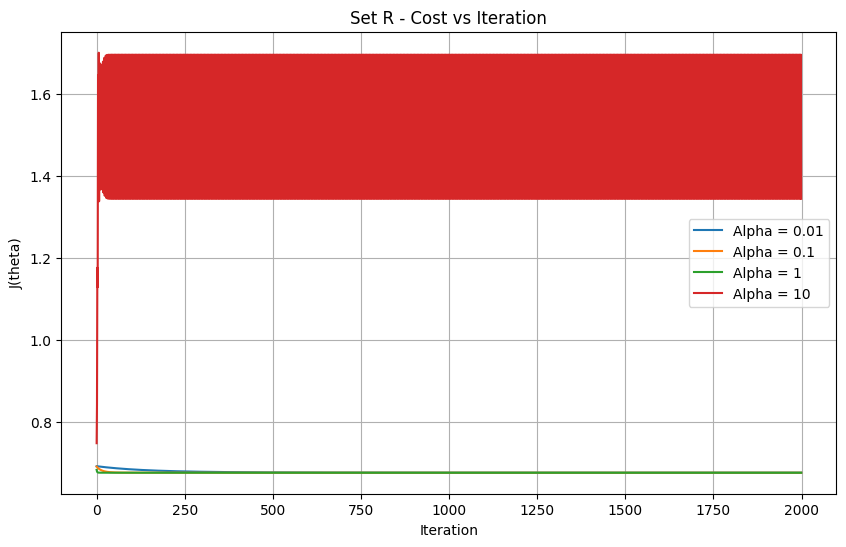

In [62]:
plt.figure(figsize=(10, 6))

plt.plot(
    cost_R_001,
    label="Alpha = 0.01"
)

plt.plot(
    cost_R_01,
    label="Alpha = 0.1"
)

plt.plot(
    cost_R_1,
    label="Alpha = 1"
)

plt.plot(
    cost_R_10,
    label="Alpha = 10"
)

plt.xlabel("Iteration")
plt.ylabel("J(theta)")
plt.title("Set R - Cost vs Iteration")
plt.legend()
plt.grid(True)

plt.show()

# Graph explanation

The graph shows how the cost changes over 2000 iterations for different learning rates in Set R. A lower cost means the logistic regression model is learning better. A small learning rate, such as 0.01, may reduce the cost slowly, while a larger learning rate may reduce it faster. However, a very high learning rate, such as 10, may cause the cost to increase or become unstable. We choose the largest learning rate for which the cost decreases at every iteration.

#3.4.6 Find Largest Valid α for Set R

In [63]:
alphas = [0.01, 0.1, 1, 10]

cost_R_results = {
    0.01: cost_R_001,
    0.1: cost_R_01,
    1: cost_R_1,
    10: cost_R_10
}

valid_alphas_R = []

for alpha in alphas:

    costs = cost_R_results[alpha]

    # Difference between consecutive costs
    differences = np.diff(costs)

    # Cost must decrease at every iteration
    if np.all(differences < 0):

        valid_alphas_R.append(alpha)

print("**** Valid Alpha Values for Set R ****")
print(valid_alphas_R)
if len(valid_alphas_R) > 0:
    best_alpha_R = max(valid_alphas_R)
    print("Largest Valid Alpha for Set R:")
    print(best_alpha_R)

else:

    print("No alpha satisfies the condition.")

**** Valid Alpha Values for Set R ****
[0.01, 0.1, 1]
Largest Valid Alpha for Set R:
1


# 3.4.7 Set Q — Test α Values

In [64]:
theta_Q_001, cost_Q_001 = fit_logistic(
    X_Q_train,
    y_train,
    0.01,
    2000
)

print("**** Set Q - Alpha = 0.01 ****")
print("Initial Cost:", cost_Q_001[0])
print("Final Cost:", cost_Q_001[-1])

**** Set Q - Alpha = 0.01 ****
Initial Cost: 0.6887665565692869
Final Cost: 0.20058062446092614


#3.4.8 α = 0.1

In [65]:
theta_Q_01, cost_Q_01 = fit_logistic(
    X_Q_train,
    y_train,
    0.1,
    2000
)

print("**** Set Q - Alpha = 0.1 ****")
print("Initial Cost:", cost_Q_01[0])
print("Final Cost:", cost_Q_01[-1])

**** Set Q - Alpha = 0.1 ****
Initial Cost: 0.6506014422122477
Final Cost: 0.13996957946776992


# 3.4.9 α = 1

In [66]:
theta_Q_1, cost_Q_1 = fit_logistic(
    X_Q_train,
    y_train,
    1,
    2000
)

print("**** Set Q - Alpha = 1 ****")
print("Initial Cost:", cost_Q_1[0])
print("Final Cost:", cost_Q_1[-1])

**** Set Q - Alpha = 1 ****
Initial Cost: 0.38380891721844357
Final Cost: 0.08898882056478556


# 3.4.10 α = 10

In [67]:
theta_Q_10, cost_Q_10 = fit_logistic(
    X_Q_train,
    y_train,
    10,
    2000
)

print("**** Set Q - Alpha = 10 ****")
print("Initial Cost:", cost_Q_10[0])
print("Final Cost:", cost_Q_10[-1])

**** Set Q - Alpha = 10 ****
Initial Cost: 0.45065148937183347
Final Cost: 0.05343427118405189


#3.4.11 Plot All Four α Values for Set Q

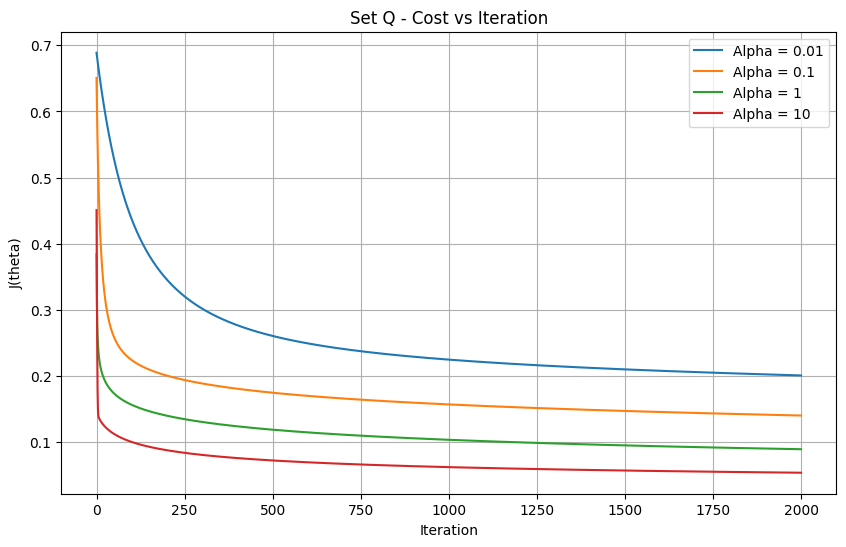

In [68]:
plt.figure(figsize=(10, 6))
plt.plot(
    cost_Q_001,
    label="Alpha = 0.01"
)

plt.plot(
    cost_Q_01,
    label="Alpha = 0.1"
)

plt.plot(
    cost_Q_1,
    label="Alpha = 1"
)

plt.plot(
    cost_Q_10,
    label="Alpha = 10"
)

plt.xlabel("Iteration")
plt.ylabel("J(theta)")

plt.title("Set Q - Cost vs Iteration")

plt.legend()
plt.grid(True)

plt.show()

#Explantion of graph

The graph shows how the cost changes over 2000 iterations for different learning rates in Set Q, which includes the original features and their squared values. A lower cost means the logistic regression model is learning better. A small learning rate may reduce the cost slowly, while a larger learning rate may reduce it faster. However, a very high learning rate may cause the cost to increase or become unstable. We choose the largest learning rate for which the cost decreases at every iteration.

#3.4.10 Find Largest Valid α for Set Q

In [69]:
cost_Q_results = {
    0.01: cost_Q_001,
    0.1: cost_Q_01,
    1: cost_Q_1,
    10: cost_Q_10
}

valid_alphas_Q = []

for alpha in alphas:

    costs = cost_Q_results[alpha]

    differences = np.diff(costs)

    if np.all(differences < 0):

        valid_alphas_Q.append(alpha)

print("**** Valid Alpha Values for Set Q ****")
print(valid_alphas_Q)

if len(valid_alphas_Q) > 0:

    best_alpha_Q = max(valid_alphas_Q)

    print("Largest Valid Alpha for Set Q:")
    print(best_alpha_Q)

else:

    print("No alpha satisfies the condition.")

**** Valid Alpha Values for Set Q ****
[0.01, 0.1, 1, 10]
Largest Valid Alpha for Set Q:
10


#3.5 — Train Final Models

#3.5.1 Display Chosen α Values

In [70]:
print("**************************************")
print("       CHOSEN ALPHA VALUES")
print("**************************************")

print("Set R Alpha:", best_alpha_R)

print("Set Q Alpha:", best_alpha_Q)

**************************************
       CHOSEN ALPHA VALUES
**************************************
Set R Alpha: 1
Set Q Alpha: 10


#3.5.2 Final Set R Model
Train Set R

In [71]:
theta_R_final, cost_R_final = fit_logistic(
    X_R_train,
    y_train,
    best_alpha_R,
    2000
)

print("**** Final Set R Model ****")

print("Alpha:", best_alpha_R)

print("Iterations:", 2000)

print("Final Cost:", cost_R_final[-1])

**** Final Set R Model ****
Alpha: 1
Iterations: 2000
Final Cost: 0.6771611730538888


#3.5.3 Set R Training Prediction

In [72]:
y_R_train_pred = predict(
    X_R_train,
    theta_R_final
)

print("**** Set R Training Predictions ****")
print(y_R_train_pred[:20])

**** Set R Training Predictions ****
[0 1 1 0 0 0 1 1 0 1 0 1 0 0 0 0 0 0 0 1]


#3.5.4 Set R Training Accuracy

In [73]:
accuracy_R_train = accuracy(
    y_train,
    y_R_train_pred
)

print("**** Set R Training Accuracy ****")
print(accuracy_R_train, "%")

**** Set R Training Accuracy ****
72.58333333333333 %


#3.5.5 Set R Validation Prediction

In [74]:
y_R_val_pred = predict(
    X_R_val,
    theta_R_final
)

print("**** Set R Validation Predictions ****")
print(y_R_val_pred[:20])

**** Set R Validation Predictions ****
[1 0 0 0 0 0 0 1 1 0 0 0 1 0 0 0 0 1 0 0]


#3.5.6 Set R Validation Accuracy

In [75]:
accuracy_R_val = accuracy(
    y_val,
    y_R_val_pred
)

print("**** Set R Validation Accuracy ****")
print(accuracy_R_val, "%")

**** Set R Validation Accuracy ****
73.08333333333333 %


#3.5.7 Set R — Print θ

In [76]:
R_theta_names = [
    "theta0",
    "Ia",
    "Ib",
    "Ic",
    "Va",
    "Vb",
    "Vc"
]

print("**** Set R Theta ****")

for i in range(len(theta_R_final)):

    print(
        R_theta_names[i],
        "=",
        theta_R_final[i]
    )

**** Set R Theta ****
theta0 = -0.1610120917104765
Ia = 0.08976487920056433
Ib = -0.1366799366734122
Ic = 0.21707272988451787
Va = -0.057500827853645804
Vb = 0.05438668224010488
Vc = 0.0010255260634624347


#3.5.8 Final Set Q Model

In [77]:
theta_Q_final, cost_Q_final = fit_logistic(
    X_Q_train,
    y_train,
    best_alpha_Q,
    2000
)

print("**** Final Set Q Model ****")

print("Alpha:", best_alpha_Q)

print("Iterations:", 2000)

print("Final Cost:", cost_Q_final[-1])

**** Final Set Q Model ****
Alpha: 10
Iterations: 2000
Final Cost: 0.05343427118405189


#3.5.9 Set Q Training Prediction

In [78]:
y_Q_train_pred = predict(
    X_Q_train,
    theta_Q_final
)

print("**** Set Q Training Predictions ****")
print(y_Q_train_pred[:20])

**** Set Q Training Predictions ****
[0 1 1 0 0 0 1 1 0 1 0 1 0 1 0 1 0 1 1 1]


#3.5.10 Set Q Training Accuracy

In [79]:
accuracy_Q_train = accuracy(
    y_train,
    y_Q_train_pred
)

print("**** Set Q Training Accuracy ****")
print(accuracy_Q_train, "%")

**** Set Q Training Accuracy ****
97.875 %


#3.5.11 Set Q Validation Prediction

In [80]:
y_Q_val_pred = predict(
    X_Q_val,
    theta_Q_final
)

print("**** Set Q Validation Predictions ****")
print(y_Q_val_pred[:20])

**** Set Q Validation Predictions ****
[1 0 0 0 1 0 0 1 1 0 1 0 1 0 1 0 0 1 0 0]


#3.5.12 Set Q Validation Accuracy

In [81]:
accuracy_Q_val = accuracy(
    y_val,
    y_Q_val_pred
)

print("**** Set Q Validation Accuracy ****")
print(accuracy_Q_val, "%")

**** Set Q Validation Accuracy ****
97.83333333333334 %


#3.5.13 Set Q — Print θ

In [82]:
Q_theta_names = [
    "theta0",
    "Ia",
    "Ib",
    "Ic",
    "Va",
    "Vb",
    "Vc",
    "Ia^2",
    "Ib^2",
    "Ic^2",
    "Va^2",
    "Vb^2",
    "Vc^2"
]
print("**** Set Q Theta ****")
for i in range(len(theta_Q_final)):
    print(
        Q_theta_names[i],
        "=",
        theta_Q_final[i]
    )

**** Set Q Theta ****
theta0 = 24.920914122367883
Ia = 2.3272915930675713
Ib = -5.358083867219878
Ic = -1.7365031309695322
Va = -0.533568713039086
Vb = 0.4167264098060003
Vc = 0.09857962774795893
Ia^2 = 18.891238299142962
Ib^2 = 4.754255911649336
Ic^2 = 13.956918039601511
Va^2 = -6.027636434055077
Vb^2 = -6.464258365360719
Vc^2 = -6.140745456717821


#3.5.14 Final Cost Curves
Final Set R Cost

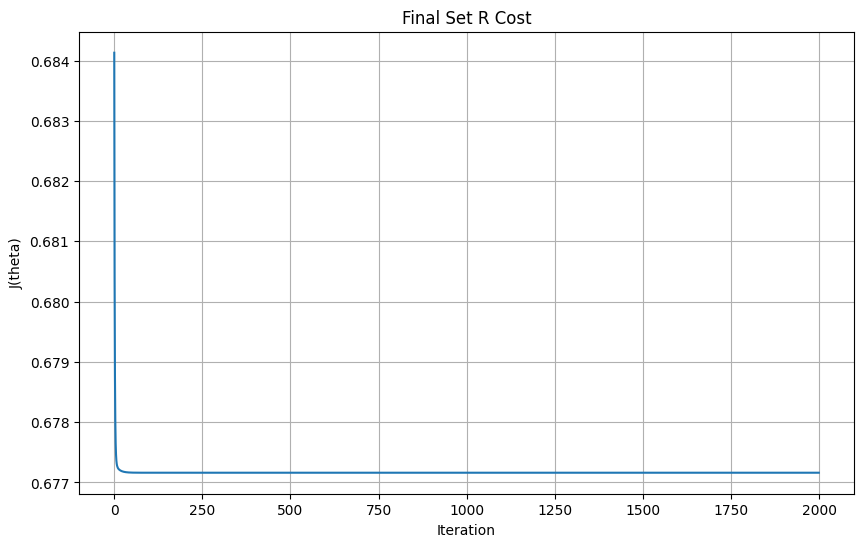

In [83]:
plt.figure(figsize=(10, 6))

plt.plot(cost_R_final)

plt.xlabel("Iteration")
plt.ylabel("J(theta)")

plt.title("Final Set R Cost")

plt.grid(True)

plt.show()

#Explanation of this graph

The graph shows how the cost changes during 2000 iterations when training the final logistic regression model using Set R and the selected learning rate. The X-axis represents the number of iterations, while the Y-axis represents the cost \(J(\theta)\). If the cost decreases over time, it means the model is learning and improving its predictions. A smooth, downward curve indicates that the model is training properly.

#3.5.15 Final Set Q Cost

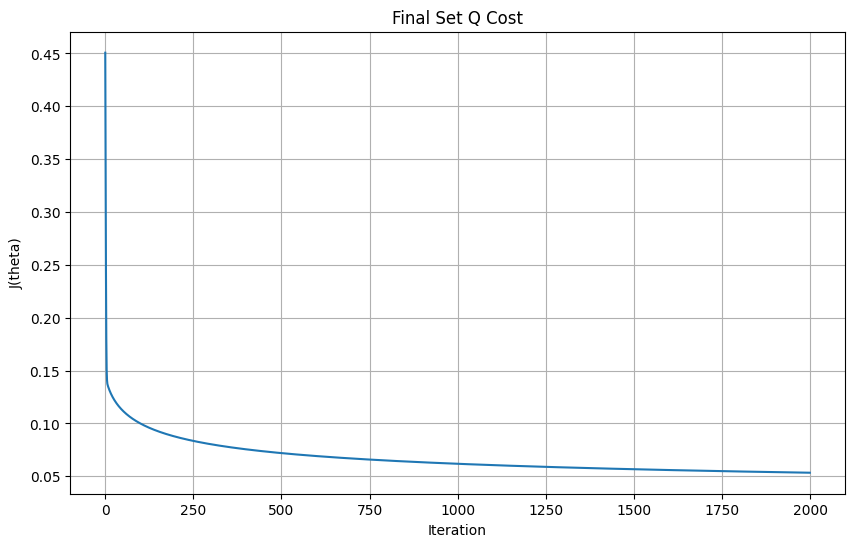

In [84]:
plt.figure(figsize=(10, 6))

plt.plot(cost_Q_final)

plt.xlabel("Iteration")
plt.ylabel("J(theta)")

plt.title("Final Set Q Cost")

plt.grid(True)

plt.show()

# Explanation of Graph

This graph shows how the cost function \(J(\theta)\) changes with each iteration for the final Set Q. The x-axis represents the number of iterations, while the y-axis represents the cost value. If the cost decreases over time, it means the model is learning and improving its predictions. When the cost becomes stable, it indicates that the model is approaching convergence. The graph helps us evaluate how effectively the model is minimizing its error during training.

#3.5.16 Accuracy Comparison

In [85]:
print("\nSet R")
print("Training Accuracy:", accuracy_R_train, "%")
print("Validation Accuracy:", accuracy_R_val, "%")

print("\nSet Q")
print("Training Accuracy:", accuracy_Q_train, "%")
print("Validation Accuracy:", accuracy_Q_val, "%")


Set R
Training Accuracy: 72.58333333333333 %
Validation Accuracy: 73.08333333333333 %

Set Q
Training Accuracy: 97.875 %
Validation Accuracy: 97.83333333333334 %


#3.5.17 Final Results Table

In [86]:
results = pd.DataFrame({
    "Feature Set": [
        "Set R",
        "Set Q"
    ],

    "Alpha": [
        best_alpha_R,
        best_alpha_Q
    ],

    "Training Accuracy (%)": [
        accuracy_R_train,
        accuracy_Q_train
    ],

    "Validation Accuracy (%)": [
        accuracy_R_val,
        accuracy_Q_val
    ],

    "Final Cost": [
        cost_R_final[-1],
        cost_Q_final[-1]
    ]
})

print("**** Final Model Comparison ****")
print(results)

**** Final Model Comparison ****
  Feature Set  Alpha  Training Accuracy (%)  Validation Accuracy (%)  \
0       Set R      1              72.583333                73.083333   
1       Set Q     10              97.875000                97.833333   

   Final Cost  
0    0.677161  
1    0.053434  


#**Task 4 — Support Vector Machines (SVM)**

In [87]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import joblib
# Use Set R: six standardized measurement features
X_svm_train = X_train_std.copy()
X_svm_val = X_val_std.copy()
# Labels for training and validation
y_svm_train = np.asarray(y_train).ravel()
y_svm_val = np.asarray(y_val).ravel()
# Check dataset dimensions
print("**** Set R for SVM ****")
print("Training features:", X_svm_train.shape)
print("Validation features:", X_svm_val.shape)
print("Training labels:", y_svm_train.shape)
print("Validation labels:", y_svm_val.shape)

# SVC cannot train with missing or infinite feature values
assert np.isfinite(X_svm_train).all(), "Training data contains NaN or infinite values."
assert np.isfinite(X_svm_val).all(), "Validation data contains NaN or infinite values."

**** Set R for SVM ****
Training features: (7200, 6)
Validation features: (2400, 6)
Training labels: (7200,)
Validation labels: (2400,)


#4.1 — Linear SVM

#4.1.1 Train and evaluate Linear SVM models

In [88]:
# Required C values
C_values = [0.1, 1, 10, 100]
# Store the results of all linear models
linear_results = []
# Store trained models
linear_models = {}
for C in C_values:
    # Create Linear SVM model
    model = SVC(kernel="linear", C=C)
    # Train using training rows only
    model.fit(X_svm_train, y_svm_train)
    # Predict labels for validation rows
    y_pred = model.predict(X_svm_val)
    # Calculate validation accuracy
    val_accuracy = accuracy_score(y_svm_val, y_pred)
    # Count total support vectors
    support_count = model.n_support_.sum()
    # Save model in memory
    linear_models[C] = model
    # Store model results
    linear_results.append({
        "Kernel": "Linear",
        "C": C,
        "gamma": "N/A",
        "Validation Accuracy": val_accuracy,
        "Support Vectors": support_count
    })

    print(f"Linear SVM | C={C}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Support Vectors: {support_count}")
    print("-" * 40)

Linear SVM | C=0.1
Validation Accuracy: 0.7258
Support Vectors: 5849
----------------------------------------
Linear SVM | C=1
Validation Accuracy: 0.7258
Support Vectors: 5843
----------------------------------------
Linear SVM | C=10
Validation Accuracy: 0.7258
Support Vectors: 5835
----------------------------------------
Linear SVM | C=100
Validation Accuracy: 0.7262
Support Vectors: 5835
----------------------------------------


#4.2 — RBF SVM

#4.2.1Train and evaluate all RBF models

In [89]:
# Required C and gamma values
C_values = [0.1, 1, 10, 100]
gamma_values = [0.1, 1]
# Store RBF model results
rbf_results = []
# Store trained RBF models
rbf_models = {}
for C in C_values:
    for gamma in gamma_values:
        # Create RBF SVM model
        model = SVC(
            kernel="rbf",
            C=C,
            gamma=gamma
        )
        # Train on training rows
        model.fit(X_svm_train, y_svm_train)
        # Predict validation labels
        y_pred = model.predict(X_svm_val)
        # Calculate validation accuracy
        val_accuracy = accuracy_score(y_svm_val, y_pred)
        # Count support vectors from all classes
        support_count = model.n_support_.sum()
        # Store trained model
        rbf_models[(C, gamma)] = model
        # Store results
        rbf_results.append({
            "Kernel": "RBF",
            "C": C,
            "gamma": gamma,
            "Validation Accuracy": val_accuracy,
            "Support Vectors": support_count
        })

        print(f"RBF SVM | C={C}, gamma={gamma}")
        print(f"Validation Accuracy: {val_accuracy:.4f}")
        print(f"Support Vectors: {support_count}")
        print("-" * 40)

RBF SVM | C=0.1, gamma=0.1
Validation Accuracy: 0.9500
Support Vectors: 1347
----------------------------------------
RBF SVM | C=0.1, gamma=1
Validation Accuracy: 0.9804
Support Vectors: 848
----------------------------------------
RBF SVM | C=1, gamma=0.1
Validation Accuracy: 0.9750
Support Vectors: 723
----------------------------------------
RBF SVM | C=1, gamma=1
Validation Accuracy: 0.9917
Support Vectors: 482
----------------------------------------
RBF SVM | C=10, gamma=0.1
Validation Accuracy: 0.9921
Support Vectors: 381
----------------------------------------
RBF SVM | C=10, gamma=1
Validation Accuracy: 0.9962
Support Vectors: 342
----------------------------------------
RBF SVM | C=100, gamma=0.1
Validation Accuracy: 0.9954
Support Vectors: 174
----------------------------------------
RBF SVM | C=100, gamma=1
Validation Accuracy: 0.9967
Support Vectors: 266
----------------------------------------


#4.3 — Create the results table

#4.3.1 Combine all 12 model results

In [90]:
# Combine four Linear models and eight RBF models
all_results = linear_results + rbf_results
# Create results table
results_df = pd.DataFrame(all_results)
# Display the required columns
results_df = results_df[
    [
        "Kernel",
        "C",
        "gamma",
        "Validation Accuracy",
        "Support Vectors"
    ]
]
print("**** SVM Model Comparison ****")
print(
    results_df.to_string(
        index=False,
        formatters={
            "Validation Accuracy": "{:.4f}".format
        }
    )
)

**** SVM Model Comparison ****
Kernel     C gamma Validation Accuracy  Support Vectors
Linear   0.1   N/A              0.7258             5849
Linear   1.0   N/A              0.7258             5843
Linear  10.0   N/A              0.7258             5835
Linear 100.0   N/A              0.7262             5835
   RBF   0.1   0.1              0.9500             1347
   RBF   0.1     1              0.9804              848
   RBF   1.0   0.1              0.9750              723
   RBF   1.0     1              0.9917              482
   RBF  10.0   0.1              0.9921              381
   RBF  10.0     1              0.9962              342
   RBF 100.0   0.1              0.9954              174
   RBF 100.0     1              0.9967              266


#4.3.2 Sort models by validation accuracy

In [91]:
# Sort from highest to lowest validation accuracy
sorted_results = results_df.sort_values(
    by="Validation Accuracy",
    ascending=False
)
print("**** SVM Models Ranked by Validation Accuracy ****")
print(
    sorted_results.to_string(
        index=False,
        formatters={
            "Validation Accuracy": "{:.4f}".format
        }
    )
)

**** SVM Models Ranked by Validation Accuracy ****
Kernel     C gamma Validation Accuracy  Support Vectors
   RBF 100.0     1              0.9967              266
   RBF  10.0     1              0.9962              342
   RBF 100.0   0.1              0.9954              174
   RBF  10.0   0.1              0.9921              381
   RBF   1.0     1              0.9917              482
   RBF   0.1     1              0.9804              848
   RBF   1.0   0.1              0.9750              723
   RBF   0.1   0.1              0.9500             1347
Linear 100.0   N/A              0.7262             5835
Linear  10.0   N/A              0.7258             5835
Linear   0.1   N/A              0.7258             5849
Linear   1.0   N/A              0.7258             5843


#4.4 Select the best model for each kernel and save it

#4.4.1 Find the best Linear and RBF settings

In [92]:
best_linear_row = (
    results_df[results_df["Kernel"] == "Linear"]
    .sort_values("Validation Accuracy", ascending=False)
    .iloc[0]
)
# Find the row with the highest validation accuracy for RBF SVM
best_rbf_row = (
    results_df[results_df["Kernel"] == "RBF"]
    .sort_values("Validation Accuracy", ascending=False)
    .iloc[0]
)
# Retrieve the corresponding trained models
best_linear_C = best_linear_row["C"]
best_linear_model = linear_models[best_linear_C]

best_rbf_C = best_rbf_row["C"]
best_rbf_gamma = best_rbf_row["gamma"]
best_rbf_model = rbf_models[(best_rbf_C, best_rbf_gamma)]

print("**** Best Linear SVM ****")
print("C:", best_linear_C)
print("Validation Accuracy:", best_linear_row["Validation Accuracy"])
print("Support Vectors:", best_linear_row["Support Vectors"])

print("\n**** Best RBF SVM ****")
print("C:", best_rbf_C)
print("Gamma:", best_rbf_gamma)
print("Validation Accuracy:", best_rbf_row["Validation Accuracy"])
print("Support Vectors:", best_rbf_row["Support Vectors"])

**** Best Linear SVM ****
C: 100.0
Validation Accuracy: 0.72625
Support Vectors: 5835

**** Best RBF SVM ****
C: 100.0
Gamma: 1
Validation Accuracy: 0.9966666666666667
Support Vectors: 266


#4.4.2 Save both models using joblib.dump

In [93]:
# Save the best Linear SVM model
joblib.dump(
    best_linear_model,
    "best_linear_svm.joblib"
)
# Save the best RBF SVM model
joblib.dump(
    best_rbf_model,
    "best_rbf_svm.joblib"
)
print("**** Models Saved Successfully ****")
print("best_linear_svm.joblib")
print("best_rbf_svm.joblib")

**** Models Saved Successfully ****
best_linear_svm.joblib
best_rbf_svm.joblib


#4.4.3 Download the saved models from Google Colab

In [94]:
from google.colab import files

# Download best Linear SVM model
files.download("best_linear_svm.joblib")

# Download best RBF SVM model
files.download("best_rbf_svm.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#**Task 5– Test once**

#5.1 — Write accuracy() and confusion_matrix() yourself

In [95]:
import numpy as np

#5.1.1 Accuracy function

In [96]:
def accuracy(y_true, y_pred):
    # Count correctly predicted rows
    correct = np.sum(y_true == y_pred)

    # Total number of rows
    total = len(y_true)

    # Calculate accuracy
    return correct / total

#5.1.2 Confusion matrix function

In [100]:
def confusion_matrix(y_true, y_pred):
    # Actual 0, predicted 0
    tn = np.sum((y_true == 0) & (y_pred == 0))

    # Actual 0, predicted 1
    fp = np.sum((y_true == 0) & (y_pred == 1))

    # Actual 1, predicted 0
    fn = np.sum((y_true == 1) & (y_pred == 0))

    # Actual 1, predicted 1
    tp = np.sum((y_true == 1) & (y_pred == 1))

    # Rows = actual classes; columns = predicted classes
    return np.array([
        [tn, fp],
        [fn, tp]
    ])

#5.2 — Evaluate the four final models on test rows

# 5.2.1 Checking Existing SVM Models

In [102]:
print("**** Checking Existing SVM Models ****")

for name, obj in list(globals().items()):
    if "svm" in name.lower() or "svc" in name.lower():
        print(name, type(obj))

**** Checking Existing SVM Models ****
SVC <class 'abc.ABCMeta'>
X_svm_train <class 'numpy.ndarray'>
X_svm_val <class 'numpy.ndarray'>
y_svm_train <class 'numpy.ndarray'>
y_svm_val <class 'numpy.ndarray'>


#5.2.2 Check that the required variables exist

In [98]:
# Check test labels and test features
print("Test rows:", len(y_test))

print("Set R test shape:", X_R_test.shape)
print("Set Q test shape:", X_Q_test.shape)
print("Standardised test shape:", X_test_std.shape)

# Check trained logistic regression parameters
print("Set R theta shape:", theta_R_final.shape)
print("Set Q theta shape:", theta_Q_final.shape)

Test rows: 2401
Set R test shape: (2401, 7)
Set Q test shape: (2401, 13)
Standardised test shape: (2401, 6)
Set R theta shape: (7,)
Set Q theta shape: (13,)


#5.2.3 Predict test rows using logistic regression

In [99]:
# Set R: Logistic regression predictions
y_R_test_pred = predict(X_R_test, theta_R_final)

# Set Q: Logistic regression predictions
y_Q_test_pred = predict(X_Q_test, theta_Q_final)

print("Set R predictions completed.")
print("Set Q predictions completed.")

print("Set R first 10 predictions:", y_R_test_pred[:10])
print("Set Q first 10 predictions:", y_Q_test_pred[:10])

Set R predictions completed.
Set Q predictions completed.
Set R first 10 predictions: [0 0 0 0 0 0 0 0 1 0]
Set Q first 10 predictions: [0 0 1 0 0 0 0 0 1 0]


#5.2.4 Predict test rows using SVM

In [103]:
# 5.2.4 Predict test rows using the best SVM models
# Use the best models selected in Task 4
y_linear_svm_test_pred = best_linear_model.predict(X_test_std)
y_rbf_svm_test_pred = best_rbf_model.predict(X_test_std)

print("**** SVM Test Predictions Completed ****")
print("Linear SVM first 10 predictions:")
print(y_linear_svm_test_pred[:10])

print("\nRBF SVM first 10 predictions:")
print(y_rbf_svm_test_pred[:10])


**** SVM Test Predictions Completed ****
Linear SVM first 10 predictions:
[0 0 0 0 0 0 0 0 0 0]

RBF SVM first 10 predictions:
[0 0 1 0 0 0 0 0 1 0]


# 5.2.5 Evaluate all four models

In [104]:

# 5.2.5 Evaluate the four final models on the test rows

print("**** Final Test Evaluation ****")

# Ensure labels and predictions are one-dimensional arrays
y_test = np.asarray(y_test).ravel()

y_R_test_pred = np.asarray(y_R_test_pred).ravel()
y_Q_test_pred = np.asarray(y_Q_test_pred).ravel()
y_linear_svm_test_pred = np.asarray(y_linear_svm_test_pred).ravel()
y_rbf_svm_test_pred = np.asarray(y_rbf_svm_test_pred).ravel()

# Store the four existing sets of test predictions
test_predictions = {
    "Logistic Regression - Set R": y_R_test_pred,
    "Logistic Regression - Set Q": y_Q_test_pred,
    "Linear SVM": y_linear_svm_test_pred,
    "RBF SVM": y_rbf_svm_test_pred
}

# Evaluate each model once using the custom functions from Task 5.1
test_results = {}

for model_name, y_pred in test_predictions.items():

    assert len(y_test) == len(y_pred), (
        f"Number of predictions does not match test labels for {model_name}"
    )

    model_accuracy = accuracy(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    tn, fp, fn, tp = cm.ravel()

    test_results[model_name] = {
        "Accuracy": model_accuracy,
        "Confusion Matrix": cm,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

    print("\nModel:", model_name)
    print("Test Accuracy:", round(model_accuracy * 100, 2), "%")
    print("Confusion Matrix:")
    print(cm)
    print("True Negatives (TN):", tn)
    print("False Positives (FP):", fp)
    print("False Negatives (FN):", fn)
    print("True Positives (TP):", tp)
    print("Missed Faults:", fn)


**** Final Test Evaluation ****

Model: Logistic Regression - Set R
Test Accuracy: 72.64 %
Confusion Matrix:
[[1305    0]
 [ 657  439]]
True Negatives (TN): 1305
False Positives (FP): 0
False Negatives (FN): 657
True Positives (TP): 439
Missed Faults: 657

Model: Logistic Regression - Set Q
Test Accuracy: 97.88 %
Confusion Matrix:
[[1299    6]
 [  45 1051]]
True Negatives (TN): 1299
False Positives (FP): 6
False Negatives (FN): 45
True Positives (TP): 1051
Missed Faults: 45

Model: Linear SVM
Test Accuracy: 73.64 %
Confusion Matrix:
[[1305    0]
 [ 633  463]]
True Negatives (TN): 1305
False Positives (FP): 0
False Negatives (FN): 633
True Positives (TP): 463
Missed Faults: 633

Model: RBF SVM
Test Accuracy: 99.58 %
Confusion Matrix:
[[1301    4]
 [   6 1090]]
True Negatives (TN): 1301
False Positives (FP): 4
False Negatives (FN): 6
True Positives (TP): 1090
Missed Faults: 6


# 5.3 For each, report accuracy, the confusion matrix, and the number of missed faults (actual fault, predicted no fault)

In [105]:

# ============================================================
# TASK 5.3: ACCURACY, CONFUSION MATRIX, AND MISSED FAULTS
# ============================================================

print("**** Task 5.3: Final Test Results ****")

models = {
    "Logistic Regression - Set R": y_R_test_pred,
    "Logistic Regression - Set Q": y_Q_test_pred,
    "Linear SVM": y_linear_svm_test_pred,
    "RBF SVM": y_rbf_svm_test_pred
}

for name, y_pred in models.items():

    y_pred = np.asarray(y_pred).ravel()
    y_true = np.asarray(y_test).ravel()

    # Calculate accuracy
    acc = accuracy(y_true, y_pred)

    # Calculate confusion matrix: [[TN, FP], [FN, TP]]
    cm = confusion_matrix(y_true, y_pred)

    # Missed faults: actual fault (1), predicted no fault (0)
    missed_faults = int(np.sum((y_true == 1) & (y_pred == 0)))

    print("\nModel:", name)
    print(f"Accuracy: {acc:.4f} ({acc * 100:.2f}%)")
    print("Confusion Matrix:")
    print(cm)
    print("Number of Missed Faults (FN):", missed_faults)


**** Task 5.3: Final Test Results ****

Model: Logistic Regression - Set R
Accuracy: 0.7264 (72.64%)
Confusion Matrix:
[[1305    0]
 [ 657  439]]
Number of Missed Faults (FN): 657

Model: Logistic Regression - Set Q
Accuracy: 0.9788 (97.88%)
Confusion Matrix:
[[1299    6]
 [  45 1051]]
Number of Missed Faults (FN): 45

Model: Linear SVM
Accuracy: 0.7364 (73.64%)
Confusion Matrix:
[[1305    0]
 [ 633  463]]
Number of Missed Faults (FN): 633

Model: RBF SVM
Accuracy: 0.9958 (99.58%)
Confusion Matrix:
[[1301    4]
 [   6 1090]]
Number of Missed Faults (FN): 6
